<a href="https://colab.research.google.com/github/selvaganapathy18/deep-learning/blob/main/DL_Exp_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Hidden Layers: [8]
Activation: relu


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Accuracy: 0.9
Test Loss: 0.2549

Hidden Layers: [8]
Activation: tanh
Test Accuracy: 0.9333
Test Loss: 0.2742

Hidden Layers: [8]
Activation: sigmoid
Test Accuracy: 0.9333
Test Loss: 0.5736

Hidden Layers: [16, 8]
Activation: relu
Test Accuracy: 0.9333
Test Loss: 0.4011

Hidden Layers: [16, 8]
Activation: tanh
Test Accuracy: 0.9333
Test Loss: 0.2063

Hidden Layers: [16, 8]
Activation: sigmoid
Test Accuracy: 0.8333
Test Loss: 0.5647

Hidden Layers: [32, 16, 8]
Activation: relu
Test Accuracy: 1.0
Test Loss: 0.067

Hidden Layers: [32, 16, 8]
Activation: tanh
Test Accuracy: 1.0
Test Loss: 0.0763

Hidden Layers: [32, 16, 8]
Activation: sigmoid
Test Accuracy: 0.6333
Test Loss: 0.6414


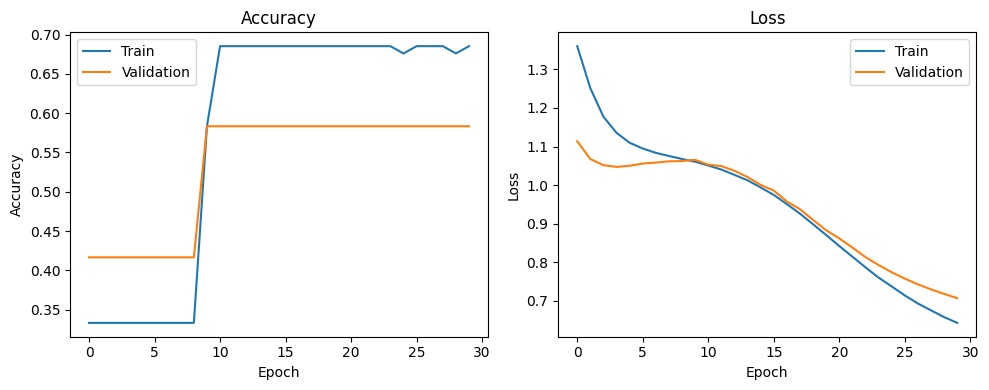


Enter Iris Flower Details


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

iris = load_iris()

X = iris.data
y = iris.target

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

def create_model(layers, activation):
    model = Sequential()

    model.add(Dense(layers[0], input_shape=(4,), activation=activation))

    for units in layers[1:]:
        model.add(Dense(units, activation=activation))

    model.add(Dense(3, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

configs = [[8], [16, 8], [32, 16, 8]]
activations = ["relu", "tanh", "sigmoid"]

for layers in configs:
    for activation in activations:

        print("\nHidden Layers:", layers)
        print("Activation:", activation)

        model = create_model(layers, activation)

        history = model.fit(
            X_train,
            y_train,
            epochs=30,
            batch_size=5,
            verbose=0,
            validation_split=0.1
        )

        loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

        print("Test Accuracy:", round(accuracy, 4))
        print("Test Loss:", round(loss, 4))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])

plt.tight_layout()
plt.show()

print("\nEnter Iris Flower Details")

a = float(input("Sepal length: "))
b = float(input("Sepal width: "))
c = float(input("Petal length: "))
d = float(input("Petal width: "))

user_input = np.array([[a, b, c, d]])
user_input = scaler.transform(user_input)

prediction = model.predict(user_input, verbose=0)
index = np.argmax(prediction)

print("Predicted Iris Species:", iris.target_names[index])